# Assignment 2 — Parkinson's Disease Classification
**Advanced Machine Learning 2026 — Team 20**

Follows the 7 tasks from the assignment brief. Fill in every `# TODO`. The test set is split
off in the very first cell and must not be touched again until Task 5 — every later cell that
needs data uses `X_trainval` / `y_trainval` only, never `X_test` / `y_test`, until the final
frozen-threshold evaluation.

Write figures/tables you want in the report to `Report/images/` and `Report/tables/`.


In [1]:
# Setup: libraries, configuration, and dataset definitions:
# - Import libraries for data analysis, visualisation, and machine learning.
# - Use scikit-learn for preprocessing, cross-validation, SVM, and MLP models.
# - Define evaluation metrics, prioritising recall and F2-score.
# - Set RANDOM_STATE=42 to ensure reproducible results.
# - Specify the dataset path and Diagnosis as the binary prediction target.
# - Exclude PatientID and DoctorInCharge as non-predictive identifiers
#   to prevent spurious associations and potential data leakage.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (confusion_matrix, recall_score, precision_score,
                              fbeta_score, classification_report)

RANDOM_STATE = 42
DATA_PATH = "parkinsons_disease_data.csv"
TARGET = "Diagnosis"
DROP_COLS = ["PatientID", "DoctorInCharge"]  # explicitly excluded per the attribute description


In [2]:
# Data loading and initial preparation:
# - Load the dataset from the specified CSV file.
# - Remove predefined columns that are irrelevant or unsuitable for prediction.
# - Check the dataset dimensions after removing these columns.
# - Display the first five rows to verify the structure and feature values.
# - Ensure DROP_COLS excludes identifiers or potential leakage variables,
#   without removing potentially useful predictors unnecessarily.

df = pd.read_csv(DATA_PATH)
df = df.drop(columns=DROP_COLS)
print(df.shape)
df.head()


(2105, 33)


,Age,Gender,Ethnicity,EducationLevel,BMI,Smoking,AlcoholConsumption,PhysicalActivity,DietQuality,SleepQuality,...,MoCA,FunctionalAssessment,Tremor,Rigidity,Bradykinesia,PosturalInstability,SpeechProblems,SleepDisorders,Constipation,Diagnosis
0,85,0,3,1,19.619878,0,5.108241,1.380660,3.893969,9.283194,...,29.181289,1.572427,1,0,0,0,0,0,0,0
1,75,0,0,2,16.247339,1,6.027648,8.409804,8.513428,5.602470,...,12.332639,4.787551,0,1,0,1,0,1,0,1
2,70,1,0,0,15.368239,0,2.242135,0.213275,6.498805,9.929824,...,29.927783,2.130686,1,0,0,0,1,0,1,1
3,52,0,0,0,15.454557,0,5.997788,1.375045,6.715033,4.196189,...,21.304268,3.391288,1,1,1,0,0,0,1,1
4,87,0,0,1,18.616042,0,9.775243,1.188607,4.657572,9.363925,...,8.336364,3.200969,0,0,0,1,0,1,0,0


## Reserve the test set now, before anything else

This has to happen before EDA-driven decisions, preprocessing fitting, or any tuning —
the brief is explicit that the test set may not influence model development in any way.
A stratified split keeps the PD/non-PD ratio the same in both halves.


In [3]:
# Data splitting for model development and final evaluation:
# - Separate features (X) from the target variable Diagnosis (y).
# - Reserve 20% of the data as an independent hold-out test set.
# - Use the remaining 80% for training and cross-validation.
# - Stratification preserves the PD/Non-PD class proportions in both sets.
# - random_state ensures reproducibility of the split.
# - The test set remains untouched until final model evaluation in Task 5.
# - All preprocessing, feature selection, and hyperparameter tuning
#   must use training data only to prevent data leakage.

X = df.drop(columns=[TARGET])
y = df[TARGET]

X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print(f"Train/val: {len(X_trainval)} rows, {y_trainval.mean():.1%} PD")
print(f"Test:      {len(X_test)} rows, {y_test.mean():.1%} PD")


#NOTE: From here on: only X_trainval / y_trainval until Task 5's final evaluation.

Train/val: 1684 rows, 61.9% PD
Test:      421 rows, 62.0% PD


## 1. Problem Framing & EDA

### Target, intended use, and error costs
**TODO** — define the prediction target (PD vs. Non-PD) and describe a plausible intended
use (e.g. a screening/triage aid flagging patients for a clinical follow-up, not a diagnostic
replacement). Explain where the model sits in that workflow, and discuss what a false negative
(missed PD case) versus a false positive (unnecessary referral) costs in that context. State
explicitly which error type you weight more heavily, and why — this choice drives your metric
and threshold choices later, so don't leave it vague.

### Evaluation metrics
**TODO** — justify your chosen metrics given the error-cost discussion above. The brief later
fixes F2 as the threshold-selection criterion (Task 5), which already tells you recall is
weighted above precision project-wide — make sure your Task 1 metric discussion is consistent
with that, not contradicting it.


In [4]:
# EDA: data quality and descriptive statistics on training/validation data only.
# - Check missing values and duplicate rows.
# - Summarise feature distributions without inspecting the held-out test set.
# - Keep the test set untouched until final evaluation.

print(X_trainval.isna().sum()[X_trainval.isna().sum() > 0])
print("\nDuplicate rows:", X_trainval.duplicated().sum())

display(X_trainval.describe().T)

Series([], dtype: int64)

Duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
Age,1684.0,69.684679,11.574388,50.000000,60.000000,70.000000,80.000000,89.000000
Gender,1684.0,0.485154,0.499928,0.000000,0.000000,0.000000,1.000000,1.000000
Ethnicity,1684.0,0.688836,1.000579,0.000000,0.000000,0.000000,1.000000,3.000000
EducationLevel,1684.0,1.336698,0.892330,0.000000,1.000000,1.000000,2.000000,3.000000
BMI,1684.0,27.173487,7.239006,15.008333,20.767862,27.137617,33.420471,39.999887
Smoking,1684.0,0.298100,0.457559,0.000000,0.000000,0.000000,1.000000,1.000000
AlcoholConsumption,1684.0,10.042942,5.675070,0.002228,5.168089,10.060746,14.772122,19.979467
PhysicalActivity,1684.0,4.991151,2.911877,0.004157,2.408328,4.986861,7.496692,9.995255
DietQuality,1684.0,4.880580,2.866819,0.000011,2.478890,4.689639,7.277106,9.995864
SleepQuality,1684.0,7.014022,1.761827,4.000497,5.502953,6.935809,8.577740,9.999821


Diagnosis
PD        0.619359
Non-PD    0.380641
Name: proportion, dtype: float64


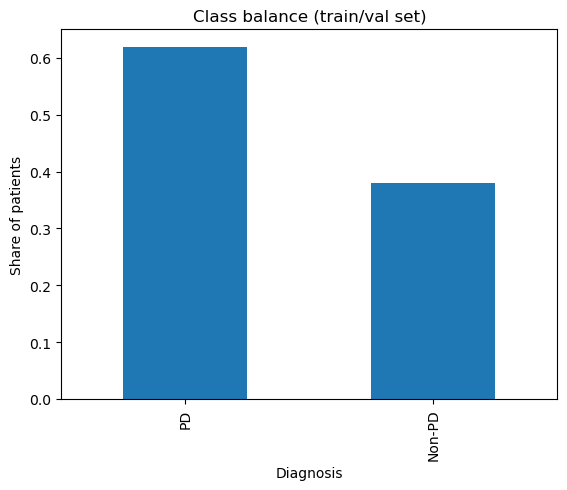

In [5]:
# EDA: class balance in the training/validation dataset:
# - PD represents 61.9% of observations, compared to 38.1% Non-PD.
# - This indicates moderate class imbalance, with PD as the majority class.
# - Stratified cross-validation will preserve class proportions across folds.
# - Recall and F2-score are prioritised over accuracy alone to minimise
#   missed PD cases (false negatives).
# - Resampling is not applied automatically; its need depends on model performance.

class_balance = y_trainval.value_counts(normalize=True).rename({0: "Non-PD", 1: "PD"})
print(class_balance)
class_balance.plot(kind="bar", title="Class balance (train/val set)")
plt.ylabel("Share of patients")
plt.savefig("Report/images/class_balance.png", dpi=150, bbox_inches="tight")  # TODO: create Report/images/ first
plt.show()


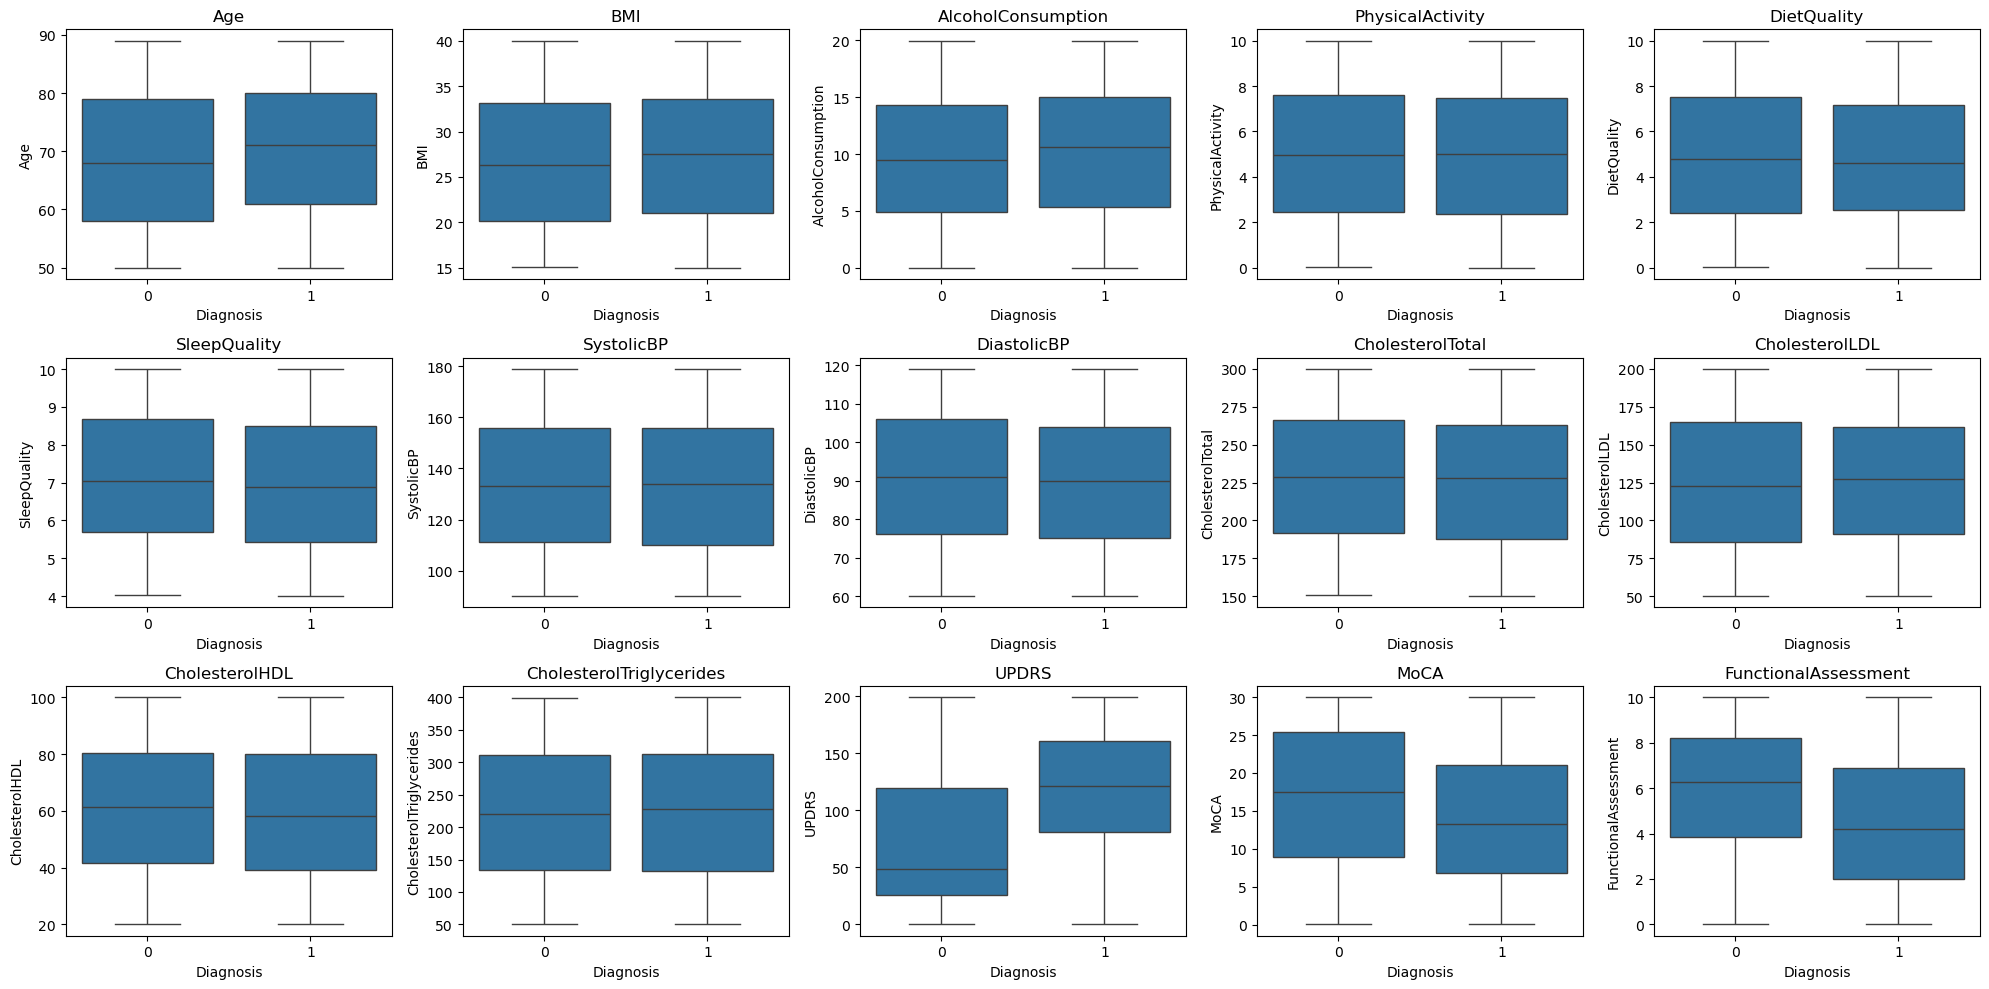

In [6]:
# EDA: outlier detection and class distribution of continuous features:
# - Boxplots compare feature distributions between PD and Non-PD.
# - Potential outliers are identified using the 1.5 × IQR criterion.
# - No visible statistical outliers were observed in either class.
# - UPDRS, FunctionalAssessment, and MoCA show the clearest class differences.
# - Other continuous features show substantial overlap between classes.
# - No outlier removal is required based on these findings.
# - Boxplots do not verify clinically valid feature ranges.

# Outlier check on the continuous clinical variables.
continuous_cols = ["Age", "BMI", "AlcoholConsumption", "PhysicalActivity", "DietQuality",
                    "SleepQuality", "SystolicBP", "DiastolicBP", "CholesterolTotal",
                    "CholesterolLDL", "CholesterolHDL", "CholesterolTriglycerides",
                    "UPDRS", "MoCA", "FunctionalAssessment"]

fig, axes = plt.subplots(3, 5, figsize=(20, 10))

for ax, col in zip(axes.flat, continuous_cols):
    sns.boxplot(
        x=y_trainval,
        y=X_trainval[col],
        ax=ax,
        showfliers=True,
        flierprops={
            "marker": "o",
            "markersize": 5,
            "markerfacecolor": "red",
            "markeredgecolor": "black",
            "alpha": 0.8
        }
    )
    ax.set_title(col)

plt.tight_layout()
plt.savefig(
    "Report/images/continuous_feature_boxplots.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

#### **Boxplot Analysis**
Boxplots were used to examine the distributions of continuous clinical variables across the PD and Non-PD groups. No statistical outliers were observed using the standard 1.5 × IQR criterion.

Most demographic, lifestyle, and cardiovascular variables showed substantial overlap between the two groups. In contrast, UPDRS, MoCA, and FunctionalAssessment showed noticeable differences in their distributions, suggesting that these variables may have predictive value for distinguishing PD from Non-PD patients.

No observations were removed based on the boxplot analysis.

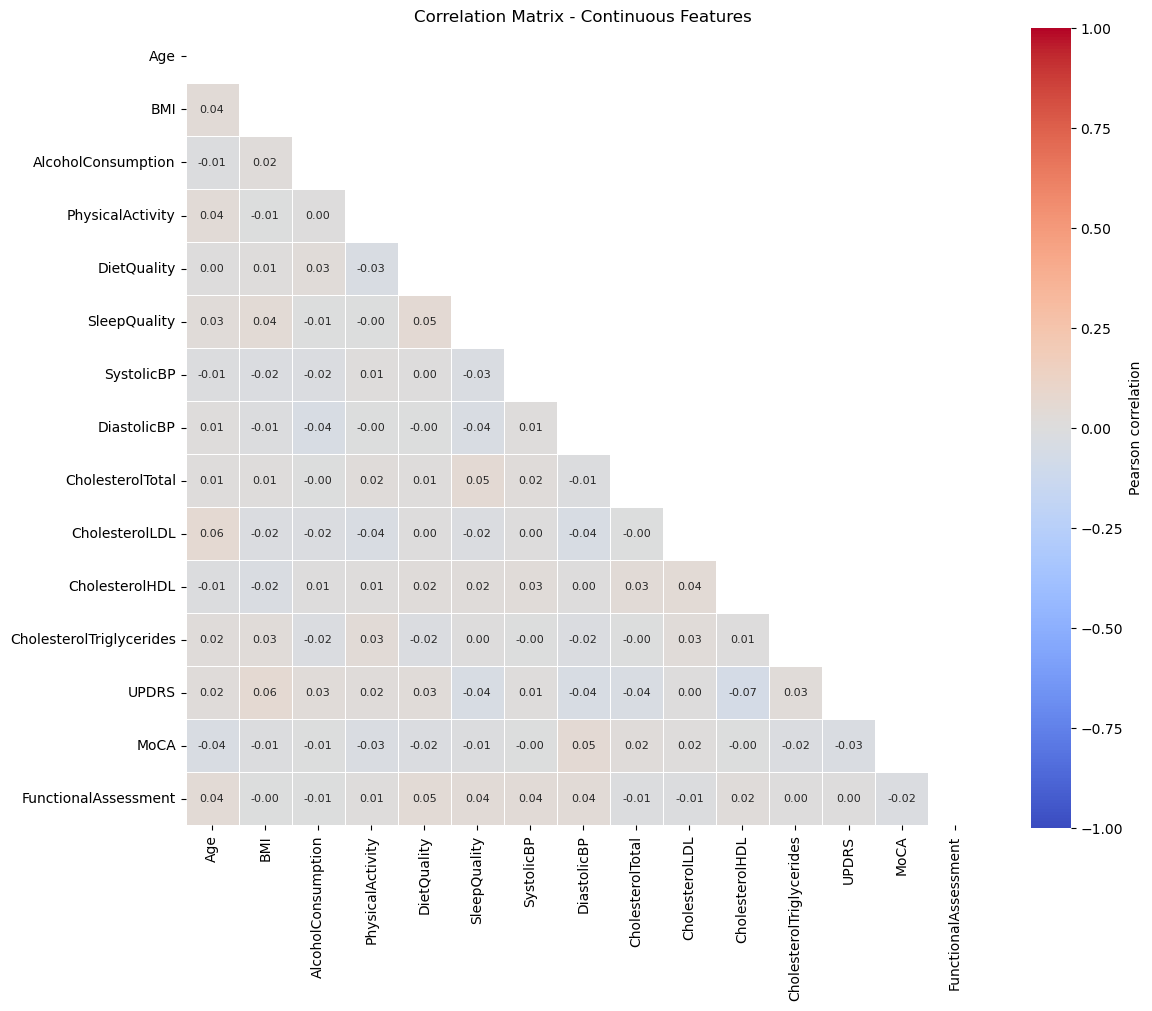

In [7]:
# EDA: Pearson correlation matrix of continuous features:
# - Examines linear relationships and potential multicollinearity.
# - Only the lower triangle is shown to avoid duplicate information.
# - Correlations are very weak (approximately -0.07 to +0.06).
# - No strongly correlated feature pairs were identified.
# - No feature removal is needed based on pairwise correlations.
# - Weak linear correlations do not exclude non-linear relationships.

corr = X_trainval[continuous_cols].corr()

# Hide upper triangle, including diagonal
mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(12, 10))

sns.heatmap(
    corr,
    mask=mask,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 8},
    linewidths=0.5,
    square=True,
    cbar_kws={"label": "Pearson correlation"}
)

plt.title("Correlation Matrix - Continuous Features")
plt.tight_layout()
plt.savefig(
    "Report/images/correlation_matrix.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

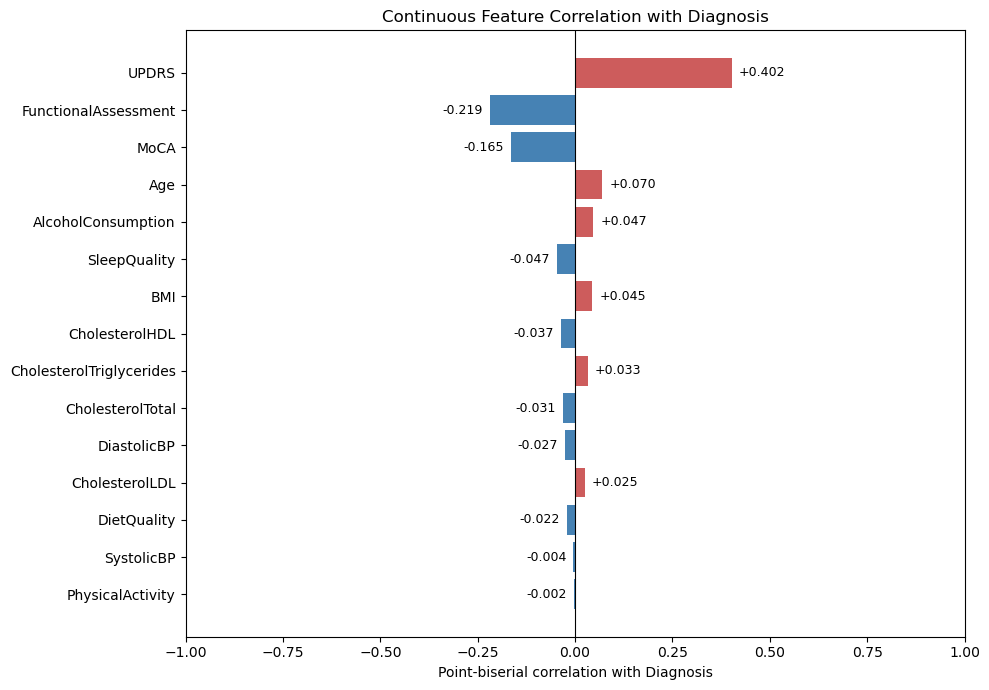

UPDRS                       0.402
FunctionalAssessment       -0.219
MoCA                       -0.165
Age                         0.070
AlcoholConsumption          0.047
SleepQuality               -0.047
BMI                         0.045
CholesterolHDL             -0.037
CholesterolTriglycerides    0.033
CholesterolTotal           -0.031
DiastolicBP                -0.027
CholesterolLDL              0.025
DietQuality                -0.022
SystolicBP                 -0.004
PhysicalActivity           -0.002
dtype: float64


In [8]:
# EDA: correlation between continuous features and Diagnosis:
# - Point-biserial correlation measures association with the binary target.
# - Features are ranked by absolute correlation strength.
# - UPDRS (r=0.402) shows the strongest positive association with PD.
# - FunctionalAssessment (r=-0.219) and MoCA (r=-0.165) show negative associations.
# - Other continuous features have very weak correlations with Diagnosis.
# - These findings support selecting UPDRS, FunctionalAssessment, and MoCA
#   as potential FIS inputs, subject to clinical relevance and availability.
# - Weak correlations do not exclude non-linear predictive relationships.

# Correlation between continuous features and Diagnosis
target_corr = X_trainval[continuous_cols].corrwith(y_trainval)

# Sort by absolute correlation (strongest first)
target_corr = target_corr.reindex(
    target_corr.abs().sort_values(ascending=False).index
)

fig, ax = plt.subplots(figsize=(10, 7))

# Colors based on correlation direction
colors = [
    "indianred" if v > 0 else "steelblue"
    for v in target_corr.values
]

bars = ax.barh(
    target_corr.index,
    target_corr.values,
    color=colors
)

# Strongest correlations at the top
ax.invert_yaxis()

# Add correlation values to each bar
for bar, value in zip(bars, target_corr.values):
    ax.annotate(
        f"{value:+.3f}",
        xy=(value, bar.get_y() + bar.get_height() / 2),
        xytext=(5 if value >= 0 else -5, 0),
        textcoords="offset points",
        ha="left" if value >= 0 else "right",
        va="center",
        fontsize=9
    )

# Formatting
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlim(-1, 1)
ax.set_xlabel("Point-biserial correlation with Diagnosis")
ax.set_ylabel("")
ax.set_title("Continuous Feature Correlation with Diagnosis")

plt.tight_layout()
plt.savefig(
    "Report/images/target_correlations.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

# Print exact correlations
print(target_corr.round(3))

### **Correlation Analysis**
The point-biserial correlation analysis shows that UPDRS has the strongest association with Diagnosis (r = 0.402), followed by FunctionalAssessment (r = -0.219) and MoCA (r = -0.165). Higher UPDRS scores are associated with Parkinson's Disease, while lower functional and cognitive assessment scores are associated with PD.

All remaining continuous features show very weak correlations with Diagnosis (|r| ≤ 0.070). These results suggest that UPDRS, FunctionalAssessment, and MoCA are the most informative individual continuous features in terms of linear association with the target.

In [9]:
# EDA checks for class balance and missing values:
# - Class distribution: assess imbalance between PD and Non-PD.
# - Class percentages: 61.9% PD and 38.1% Non-PD, indicating moderate imbalance.
# - Missing values: check data completeness before preprocessing.
# - No missing values found; imputation is therefore unnecessary.
# - Class imbalance supports using stratified cross-validation and
#   prioritising recall and F2-score over accuracy alone.

# Class balance
print("Class distribution:")
print(y_trainval.value_counts())
print("\nClass percentages:")
print((y_trainval.value_counts(normalize=True) * 100).round(1))

# Missing values
print("\nMissing values per feature:")
print(X_trainval.isnull().sum())

print("\nTotal missing values:")
print(X_trainval.isnull().sum().sum())

Class distribution:
Diagnosis
1    1043
0     641
Name: count, dtype: int64

Class percentages:
Diagnosis
1    61.9
0    38.1
Name: proportion, dtype: float64

Missing values per feature:
Age                         0
Gender                      0
Ethnicity                   0
EducationLevel              0
BMI                         0
Smoking                     0
AlcoholConsumption          0
PhysicalActivity            0
DietQuality                 0
SleepQuality                0
FamilyHistoryParkinsons     0
TraumaticBrainInjury        0
Hypertension                0
Diabetes                    0
Depression                  0
Stroke                      0
SystolicBP                  0
DiastolicBP                 0
CholesterolTotal            0
CholesterolLDL              0
CholesterolHDL              0
CholesterolTriglycerides    0
UPDRS                       0
MoCA                        0
FunctionalAssessment        0
Tremor                      0
Rigidity                    0
Br

### **EDA Findings and Implications**

The training/validation dataset contains 1,684 observations, with 61.9% diagnosed with Parkinson's Disease (PD) and 38.1% classified as Non-PD. This indicates a moderate class imbalance. No missing values were found, and the boxplots revealed no statistical outliers using the 1.5 × IQR criterion.

The correlation analysis identified UPDRS as the feature most strongly associated with Diagnosis (r = 0.402), followed by FunctionalAssessment (r = -0.219) and MoCA (r = -0.165). The boxplots confirmed visible differences between the PD and Non-PD groups for these variables. Other continuous features showed weak correlations with Diagnosis. Pairwise correlations between continuous features were also very low, suggesting no strong linear multicollinearity.

*Implications for Task 2 (Preprocessing):* No missing-value imputation or outlier removal is currently required. Feature scaling should be considered for scale-sensitive models. Given the moderate class imbalance, evaluation should prioritise recall and F2-score rather than accuracy alone. Any resampling, if used, should be applied only to the training data.

*Implications for Task 3 (FIS):* UPDRS, FunctionalAssessment, and MoCA are promising candidates for FIS inputs because of their associations with Diagnosis and their clinical interpretability. The final selection should consider the availability of these measurements at prediction time and the complexity of the fuzzy rule base.

## 2. Preprocessing & Feature Engineering

Binary/ordinal columns (Gender, Smoking, the yes/no symptom flags, etc.) need no scaling.
Continuous columns get standardized. Ethnicity and EducationLevel are categorical with more
than two levels, so they get one-hot encoded rather than treated as ordinal integers — treating
them as plain numbers would imply a false ordering.

In [10]:
# Feature groups and preprocessing choices based on EDA:
# - Continuous: standardised for scale-sensitive SVM and MLP models.
# - Categorical: one-hot encoded to avoid artificial numerical ordering.
# - Binary: retained as 0/1 without transformation.
# - All 32 original features retained: no strong pairwise correlations
#   or visible IQR outliers; near-zero variance still needs verification.
# - No imputation required, as no missing values were found.
# - Preprocessing will be fitted within each cross-validation training fold
#   to prevent data leakage.

# Feature groups
categorical_cols = ["Ethnicity", "EducationLevel"]

binary_cols = [
    "Gender", "Smoking", "FamilyHistoryParkinsons",
    "TraumaticBrainInjury", "Hypertension", "Diabetes",
    "Depression", "Stroke", "Tremor", "Rigidity",
    "Bradykinesia", "PosturalInstability", "SpeechProblems",
    "SleepDisorders", "Constipation"
]

# continuous_cols defined in Task 1
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), continuous_cols),
        ("cat", OneHotEncoder(
            handle_unknown="ignore"
        ), categorical_cols),
        ("bin", "passthrough", binary_cols)
    ]
)

In [11]:
# Model pipelines for SVM and MLP:
# - Both models use the same preprocessing for a fair comparison.
# - SVM: suitable for complex, potentially non-linear decision boundaries.
# - MLP: captures non-linear relationships and feature interactions.
# - max_iter=1000 allows sufficient iterations for MLP convergence.
# - random_state=42 ensures reproducible MLP initialisation.
# - Pipelines prevent data leakage by fitting preprocessing separately
#   within each cross-validation training fold.
# - Model hyperparameters will be optimised during cross-validation.

svm_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", SVC())
])

mlp_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", MLPClassifier(
        max_iter=1000,
        random_state=42
    ))
])

In [12]:
# Feature retention decision:
# - No constant features were identified among the 32 predictors.
# - Stroke has the lowest variation (95% identical values).
# - Rare binary features may still provide clinically relevant information.
# - No strong pairwise correlations were found among continuous features.
# - All 32 original features are retained for SVM and MLP.
# - No additional feature engineering is applied at this stage.

feature_variation = pd.DataFrame({
    "Unique values": X_trainval.nunique(),
    "Most frequent value (%)": (
        X_trainval.apply(
            lambda col: col.value_counts(normalize=True).iloc[0]
        ) * 100
    ).round(1)
})

print(
    feature_variation.sort_values(
        "Most frequent value (%)",
        ascending=False
    )
)

                          Unique values  Most frequent value (%)
Stroke                                2                     95.0
TraumaticBrainInjury                  2                     89.5
PosturalInstability                   2                     86.2
Diabetes                              2                     85.3
FamilyHistoryParkinsons               2                     85.3
Hypertension                          2                     85.2
Depression                            2                     80.0
Bradykinesia                          2                     78.9
SleepDisorders                        2                     75.5
Rigidity                              2                     74.6
SpeechProblems                        2                     70.8
Smoking                               2                     70.2
Constipation                          2                     69.7
Ethnicity                             4                     60.5
Tremor                   

### **Preprocessing and Feature Engineering**

Based on the EDA findings, all 32 predictive features were retained. No missing values, constant features, or visible statistical outliers were identified. Although Stroke showed limited variation (95% identical values), it was retained because rare clinical conditions may still provide predictive information. No strong pairwise correlations were found among continuous features, and no additional feature engineering was considered necessary.

A ColumnTransformer was defined to apply feature-specific preprocessing:
- Continuous features (15): StandardScaler to standardise numerical values for scale-sensitive SVM and MLP models.
- Categorical features (2): OneHotEncoder to represent categories without imposing artificial numerical relationships.
- Binary features (15): Retained in their original 0/1 representation.

To prevent data leakage, preprocessing is integrated into the SVM and MLP pipelines, ensuring that transformations are fitted exclusively on the training portion of each cross-validation fold. The held-out test set remains untouched until final evaluation.

For the Fuzzy Inference System (FIS), UPDRS, FunctionalAssessment, and MoCA were identified as potential inputs based on their associations with Diagnosis and clinical interpretability. Their original measurement scales will be preserved, and any data-dependent membership function parameters will be determined using training data only.

Overall, the preprocessing strategy maintains the available predictive information while supporting a consistent, reproducible, and leakage-free comparison of the models.

## 3. Models

All three models predict `Diagnosis` (1 = PD) and expose `predict_proba`, so Task 5 can apply
the same F2 threshold rule to each of them. SVM and MLP share Gilbert's `preprocessor` inside a
`Pipeline`; the FIS has its own, hand-built preprocessing (see below).

### SVM — linear and RBF kernels
One SVM family, two kernels as candidate configurations; Task 4 searches both in a single grid
and keeps the best one. `SVC(probability=True)` is deprecated from scikit-learn 1.9, so the SVC
is wrapped in `CalibratedClassifierCV(method="sigmoid", ensemble=False)` (Platt scaling). The
sigmoid is monotone in the SVM decision value, so it does not change the ranking of patients,
only puts the scores on a [0, 1] scale for the threshold search.


In [13]:
# SVM pipeline (single definition; the grid in Task 4 sets kernel, C and gamma):
# - preprocessor from Task 2 is refitted inside every CV training fold.
# - Platt scaling (sigmoid) fitted with an internal 5-fold split of the training data only.
# - Kernel, C and gamma are set by the Task 4 grid.
from sklearn.calibration import CalibratedClassifierCV

svm_pipeline = Pipeline([
    ("preprocess", preprocessor),
    ("clf", CalibratedClassifierCV(SVC(), method="sigmoid", cv=5, ensemble=False)),
])
svm_pipeline

,steps,"[('preprocess', ...), ('clf', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


### MLP
A feed-forward network with ReLU hidden layers and the Adam optimiser. Width/depth and the L2
penalty `alpha` are tuned in Task 4. Early stopping is deliberately off, so `alpha` is the only
regulariser and its effect on the bias-variance trade-off can be read directly from the CV
results. A fixed `random_state` makes the weight initialisation reproducible.


In [14]:
mlp_pipeline = Pipeline([
    ("preprocess", preprocessor),
    ("clf", MLPClassifier(activation="relu", solver="adam", learning_rate_init=0.001,
                          max_iter=2000, random_state=RANDOM_STATE)),
])
mlp_pipeline

,steps,"[('preprocess', ...), ('clf', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


### Fuzzy Inference System (FIS)

**Inputs (4 continuous).** Each one is traceable to the attribute description, and the
literature only fixes the direction or a published cut-off:

| Input | Source | What the source gives the model |
|---|---|---|
| UPDRS | Attribute description ("higher scores indicate greater disease severity"); MDS-UPDRS is the standard PD rating scale (Goetz et al., 2008) | Higher = abnormal. Universe 0–199. |
| MoCA | Attribute description ("lower scores indicate cognitive impairment"); published cut-off <26 = impaired (Nasreddine et al., 2005) | Lower = abnormal, crossover fixed at 26. Universe 0–30. |
| FunctionalAssessment | Attribute description ("lower scores indicate greater impairment") | Lower = abnormal. Universe 0–10. |
| Age | PD prevalence rises steeply with age, 107 → 428 per 100,000 from age 50–59 to 60–69 (Pringsheim et al., 2014) | Higher = abnormal, source crossover 60. Universe 50–90. |

SleepQuality (in the earlier draft) is dropped. Its PD rate is flat across quintiles in the
training data (0.59–0.66), and the PD literature concerns sleep *disorders*, which is a binary
column and cannot be a continuous FIS input.

**Membership functions (2 per input).** Each input has a "normal" and an "abnormal" set,
built as complementary trapezoids around a crossover point *c* with transition half-width *h*.
The EDA (Task 1) shows that the PD rate behaves like a step for all three clinical scores, so
two sets describe the data better than three. Crossovers either come from the sources above
(`breakpoints="source"`; scale midpoints where no source gives a value) or are learned from the
training fold with a depth-1 decision tree per input (`breakpoints="training"`; MoCA stays at 26).

**Rules (7)**, risk output sets low / medium / high on [0, 1]:

| # | IF | THEN | Reasoning |
|---|---|---|---|
| R1 | UPDRS high AND MoCA impaired AND FA impaired | high | Motor severity plus both non-motor/functional impairments |
| R2 | UPDRS high AND (MoCA impaired OR FA impaired) | medium | Motor severity with one supporting impairment |
| R3 | UPDRS high AND Age older | medium | Age is the main epidemiological risk factor (Pringsheim et al., 2014) |
| R4 | UPDRS low AND MoCA impaired AND FA impaired | medium | Non-motor/functional impairment without motor severity |
| R5 | UPDRS low AND MoCA normal | low | No motor severity, normal cognition |
| R6 | UPDRS low AND FA normal | low | No motor severity, normal function |
| R7 | MoCA normal AND FA normal | low | No cognitive or functional impairment |

Mamdani inference (Mamdani & Assilian, 1975): min for AND, max for OR, clipping implication,
max aggregation, centroid defuzzification. The rule base covers the whole input space,
because UPDRS high + UPDRS low = 1 and R1–R7 condition on both sides.


In [15]:
# Fuzzy Inference System (Mamdani, centroid defuzzification), wrapped as a scikit-learn
# estimator so it can be validated on exactly the same CV folds as SVM and MLP.
# - Inputs: 4 continuous variables (see the traceability table above).
# - 2 membership functions per input ("normal" / "abnormal" side of a crossover point),
#   built as complementary trapezoids: the two memberships always sum to 1.
# - Universes come from the attribute description (fixed, not data-dependent).
# - Crossover points are the only data-dependent part. With breakpoints="training" they are
#   learned in fit() from the training rows only (a depth-1 decision tree per input), so in CV
#   each fold learns its own crossovers and the validation fold never influences them.
# - MoCA always uses the published cut-off of 26 (Nasreddine et al., 2005).
# - 7 rules, min for AND, max for OR, clipping implication, max aggregation.
# - The centroid lies in [1/6, 5/6] for these output sets, so it is rescaled linearly to
#   [0, 1]. That mapping depends only on the output sets, not on data.

import skfuzzy as fuzz
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.tree import DecisionTreeClassifier

FIS_INPUTS = ["UPDRS", "MoCA", "FunctionalAssessment", "Age"]

# Universe of discourse per input, from Parkinsons_Dataset_Attribute_Description.txt
FIS_UNIVERSE = {"UPDRS": (0, 199), "MoCA": (0, 30), "FunctionalAssessment": (0, 10), "Age": (50, 90)}

# Which side of the crossover is the "abnormal" (risk-raising) side, from the description:
# higher UPDRS = more severe, lower MoCA = cognitive impairment, lower FA = more impaired.
FIS_HIGH_IS_ABNORMAL = {"UPDRS": True, "MoCA": False, "FunctionalAssessment": False, "Age": True}

# Crossovers that need no data: MoCA 26 (published cut-off), Age 60 (prevalence rises
# steeply from age 60, Pringsheim et al., 2014), UPDRS and FA at the midpoint of their scale.
FIS_SOURCE_CROSSOVER = {"UPDRS": 99.5, "MoCA": 26.0, "FunctionalAssessment": 5.0, "Age": 60.0}

FIS_RULES = [
    # (antecedent description for the report, consequent)
    ("UPDRS high AND MoCA impaired AND FA impaired", "high"),
    ("UPDRS high AND (MoCA impaired OR FA impaired)", "medium"),
    ("UPDRS high AND Age older", "medium"),
    ("UPDRS low AND MoCA impaired AND FA impaired", "medium"),
    ("UPDRS low AND MoCA normal", "low"),
    ("UPDRS low AND FA normal", "low"),
    ("MoCA normal AND FA normal", "low"),
]

RISK_UNIVERSE = np.linspace(0, 1, 101)
RISK_SETS = {
    "low": fuzz.trimf(RISK_UNIVERSE, [0, 0, 0.5]),
    "medium": fuzz.trimf(RISK_UNIVERSE, [0, 0.5, 1]),
    "high": fuzz.trimf(RISK_UNIVERSE, [0.5, 1, 1]),
}
CENTROID_MIN = fuzz.defuzz(RISK_UNIVERSE, RISK_SETS["low"], "centroid")   # = 1/6
CENTROID_MAX = fuzz.defuzz(RISK_UNIVERSE, RISK_SETS["high"], "centroid")  # = 5/6


def abnormal_membership(x, crossover, half_width, high_is_abnormal):
    """Degree to which x is on the abnormal side: 0 below c-h, linear ramp, 1 above c+h."""
    mu_high = np.clip((x - (crossover - half_width)) / (2 * half_width), 0, 1)
    return mu_high if high_is_abnormal else 1 - mu_high


class FuzzyPDRisk(ClassifierMixin, BaseEstimator):
    """Mamdani FIS returning a PD risk score in [0, 1] through predict_proba.

    breakpoints : "source"   -> crossovers from FIS_SOURCE_CROSSOVER (no data used)
                  "training" -> UPDRS, FA and Age crossovers learned from training rows;
                                MoCA stays at the published cut-off of 26
    width       : half-width of the fuzzy transition as a fraction of the input's universe
    """

    def __init__(self, breakpoints="training", width=0.05):
        self.breakpoints = breakpoints
        self.width = width

    def fit(self, X, y):
        X = pd.DataFrame(X)[FIS_INPUTS]
        self.classes_ = np.array([0, 1])
        self.crossover_ = dict(FIS_SOURCE_CROSSOVER)
        if self.breakpoints == "training":
            for col in ["UPDRS", "FunctionalAssessment", "Age"]:
                stump = DecisionTreeClassifier(max_depth=1).fit(X[[col]], y)
                self.crossover_[col] = float(stump.tree_.threshold[0])
        self.half_width_ = {c: self.width * (hi - lo) for c, (lo, hi) in FIS_UNIVERSE.items()}
        return self

    def memberships(self, X):
        """Abnormal-side membership per input (normal side = 1 - abnormal)."""
        X = pd.DataFrame(X)[FIS_INPUTS]
        mu = {}
        for col in FIS_INPUTS:
            lo, hi = FIS_UNIVERSE[col]
            x = X[col].clip(lo, hi).to_numpy(float)  # values outside the universe are clipped
            mu[col] = abnormal_membership(x, self.crossover_[col], self.half_width_[col],
                                          FIS_HIGH_IS_ABNORMAL[col])
        return mu

    def rule_strengths(self, X):
        mu = self.memberships(X)
        U, M, F, A = (mu[c] for c in FIS_INPUTS)  # abnormal: UPDRS high, MoCA/FA impaired, older
        return np.column_stack([
            np.minimum.reduce([U, M, F]),          # R1 -> high
            np.minimum(U, np.maximum(M, F)),       # R2 -> medium
            np.minimum(U, A),                      # R3 -> medium
            np.minimum.reduce([1 - U, M, F]),      # R4 -> medium
            np.minimum(1 - U, 1 - M),              # R5 -> low
            np.minimum(1 - U, 1 - F),              # R6 -> low
            np.minimum(1 - M, 1 - F),              # R7 -> low
        ])

    def risk_score(self, X):
        w = self.rule_strengths(X)
        consequents = np.array([c for _, c in FIS_RULES])
        aggregated = np.zeros((w.shape[0], RISK_UNIVERSE.size))
        for term, out_set in RISK_SETS.items():
            w_term = w[:, consequents == term].max(axis=1)              # OR over rules
            aggregated = np.maximum(aggregated, np.minimum(w_term[:, None], out_set[None, :]))
        if np.any(aggregated.sum(axis=1) == 0):  # cannot happen with this rule base
            raise ValueError("No rule fired for some rows; check rule coverage.")
        centroid = np.array([fuzz.defuzz(RISK_UNIVERSE, row, "centroid") for row in aggregated])
        return np.clip((centroid - CENTROID_MIN) / (CENTROID_MAX - CENTROID_MIN), 0, 1)

    def predict_proba(self, X):
        risk = self.risk_score(X)
        return np.column_stack([1 - risk, risk])

    def decision_function(self, X):
        return self.risk_score(X)

    def predict(self, X):
        return (self.risk_score(X) >= 0.5).astype(int)

In [16]:
# Check 1: the vectorised FIS gives the same output as scikit-fuzzy's own control API.
# (The membership-function figure is drawn in Task 4, for the FIS variant selected there.)
from skfuzzy import control as ctrl

fis_demo = FuzzyPDRisk(breakpoints="training", width=0.05).fit(X_trainval, y_trainval)
print("Crossovers learned on X_trainval:", {k: round(v, 2) for k, v in fis_demo.crossover_.items()})

ants = {}
for col in FIS_INPUTS:
    lo, hi = FIS_UNIVERSE[col]
    universe = np.linspace(lo, hi, 2001)
    ant = ctrl.Antecedent(universe, col)
    ab = abnormal_membership(universe, fis_demo.crossover_[col], fis_demo.half_width_[col],
                             FIS_HIGH_IS_ABNORMAL[col])
    ant["abnormal"], ant["normal"] = ab, 1 - ab
    ants[col] = ant
risk = ctrl.Consequent(RISK_UNIVERSE, "risk", defuzzify_method="centroid")
for term, out_set in RISK_SETS.items():
    risk[term] = out_set
U, M, F, A = (ants[c] for c in FIS_INPUTS)
ref_rules = [
    ctrl.Rule(U["abnormal"] & M["abnormal"] & F["abnormal"], risk["high"]),
    ctrl.Rule(U["abnormal"] & (M["abnormal"] | F["abnormal"]), risk["medium"]),
    ctrl.Rule(U["abnormal"] & A["abnormal"], risk["medium"]),
    ctrl.Rule(U["normal"] & M["abnormal"] & F["abnormal"], risk["medium"]),
    ctrl.Rule(U["normal"] & M["normal"], risk["low"]),
    ctrl.Rule(U["normal"] & F["normal"], risk["low"]),
    ctrl.Rule(M["normal"] & F["normal"], risk["low"]),
]
sim = ctrl.ControlSystemSimulation(ctrl.ControlSystem(ref_rules))
check_rows = X_trainval.iloc[:200]
ref = []
for _, row in check_rows.iterrows():
    for col in FIS_INPUTS:
        sim.input[col] = row[col]
    sim.compute()
    ref.append((sim.output["risk"] - CENTROID_MIN) / (CENTROID_MAX - CENTROID_MIN))
print("Max |difference| vs skfuzzy.control on 200 rows:",
      f"{np.max(np.abs(np.array(ref) - fis_demo.risk_score(check_rows))):.1e}")

Crossovers learned on X_trainval: {'UPDRS': 49.92, 'MoCA': 26.0, 'FunctionalAssessment': 4.99, 'Age': 59.5}
Max |difference| vs skfuzzy.control on 200 rows: 6.9e-05


## 4. Validation & Hyperparameter Optimization

**Validation strategy.** Every model is developed on `X_trainval` only (1,684 rows), with the
same `StratifiedKFold(5, shuffle=True, random_state=42)` folds, so all CV scores are directly
comparable. Five folds leave about 337 validation rows per fold (≈128 Non-PD), which is enough
for a stable average precision, and stratification keeps the 62/38 ratio in every fold.
Preprocessing (scaling, one-hot encoding, FIS crossovers, Platt sigmoid) is refitted inside
each training fold.

**Search objective: average precision (AP), not `recall`.** The decision threshold is chosen
later (Task 5, max F2), so model selection should reward a good *ranking* of patients, not a
good prediction at the default 0.5 cut-off. Recall at 0.5 can be maximised by a model that
labels everyone as PD (the cell below shows this). AP summarises precision over all recall
levels, so the threshold can be tuned afterwards. Recall, F2 at 0.5 and ROC AUC are logged
for every configuration as secondary information.

**Budgets.** SVM family: 5 linear + 15 RBF = 20 configurations. MLP: 4 architectures × 5
`alpha` = 20. Each grid was fixed in advance and run once. The RBF `gamma` values are 0.1×,
1× and 10× scikit-learn's `scale` heuristic (1 / (n_features · Var(X)) ≈ 0.051 on the
preprocessed training data).


In [17]:
from sklearn.metrics import make_scorer

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "ap": "average_precision",                     # selection criterion (refit)
    "roc_auc": "roc_auc",
    "recall": "recall",                            # at the default 0.5 cut-off
    "f2": make_scorer(fbeta_score, beta=2),         # at the default 0.5 cut-off
}

svm_param_grid = [
    {"clf__estimator__kernel": ["linear"],
     "clf__estimator__C": [0.001, 0.01, 0.1, 1, 10]},                          # 5
    {"clf__estimator__kernel": ["rbf"],
     "clf__estimator__C": [0.1, 1, 10, 100, 1000],
     "clf__estimator__gamma": [0.005, 0.05, 0.5]},                              # 15
]

svm_grid = GridSearchCV(svm_pipeline, svm_param_grid, scoring=scoring, refit="ap",
                        cv=cv, n_jobs=-1, return_train_score=True)
svm_grid.fit(X_trainval, y_trainval)

n_svm = len(svm_grid.cv_results_["params"])
assert n_svm <= 20, n_svm
print("SVM configurations evaluated:", n_svm)
print("Best SVM params:", svm_grid.best_params_)
print(f"Best SVM CV AP (search score, not the final reported number): {svm_grid.best_score_:.3f}")

SVM configurations evaluated: 20
Best SVM params: {'clf__estimator__C': 10, 'clf__estimator__gamma': 0.005, 'clf__estimator__kernel': 'rbf'}
Best SVM CV AP (search score, not the final reported number): 0.937


In [18]:
mlp_param_grid = {
    "clf__hidden_layer_sizes": [(8,), (32,), (64,), (32, 16)],
    "clf__alpha": [0.001, 0.01, 0.1, 1, 10],
}

mlp_grid = GridSearchCV(mlp_pipeline, mlp_param_grid, scoring=scoring, refit="ap",
                        cv=cv, n_jobs=-1, return_train_score=True)
mlp_grid.fit(X_trainval, y_trainval)

n_mlp = len(mlp_grid.cv_results_["params"])
assert n_mlp <= 20, n_mlp
print("MLP configurations evaluated:", n_mlp)
print("Best MLP params:", mlp_grid.best_params_)
print(f"Best MLP CV AP (search score, not the final reported number): {mlp_grid.best_score_:.3f}")

MLP configurations evaluated: 20
Best MLP params: {'clf__alpha': 1, 'clf__hidden_layer_sizes': (32,)}
Best MLP CV AP (search score, not the final reported number): 0.946


In [19]:
# FIS validation: no gradient-based training, but two design choices were left open and are
# compared on the same 5 folds, with the same AP criterion as SVM/MLP:
#   breakpoints: "source" (no data) vs "training" (crossovers learned per training fold)
#   width:       narrow (h = 2.5% of the universe) vs wide (h = 10%)
# 4 variants, decided before running. Inputs, MF count and rules are fixed (above); they are
# not tuned. The test set is not used.
fis_param_grid = {"breakpoints": ["source", "training"], "width": [0.025, 0.10]}

fis_grid = GridSearchCV(FuzzyPDRisk(), fis_param_grid, scoring=scoring, refit="ap",
                        cv=cv, n_jobs=1, return_train_score=True)
fis_grid.fit(X_trainval, y_trainval)

print("FIS variants evaluated:", len(fis_grid.cv_results_["params"]))
print("Best FIS variant:", fis_grid.best_params_)
print(f"Best FIS CV AP (search score): {fis_grid.best_score_:.3f}")
print("Crossovers after refit on X_trainval:",
      {k: round(v, 2) for k, v in fis_grid.best_estimator_.crossover_.items()})

FIS variants evaluated: 4
Best FIS variant: {'breakpoints': 'training', 'width': 0.1}
Best FIS CV AP (search score): 0.866
Crossovers after refit on X_trainval: {'UPDRS': 49.92, 'MoCA': 26.0, 'FunctionalAssessment': 4.99, 'Age': 59.5}


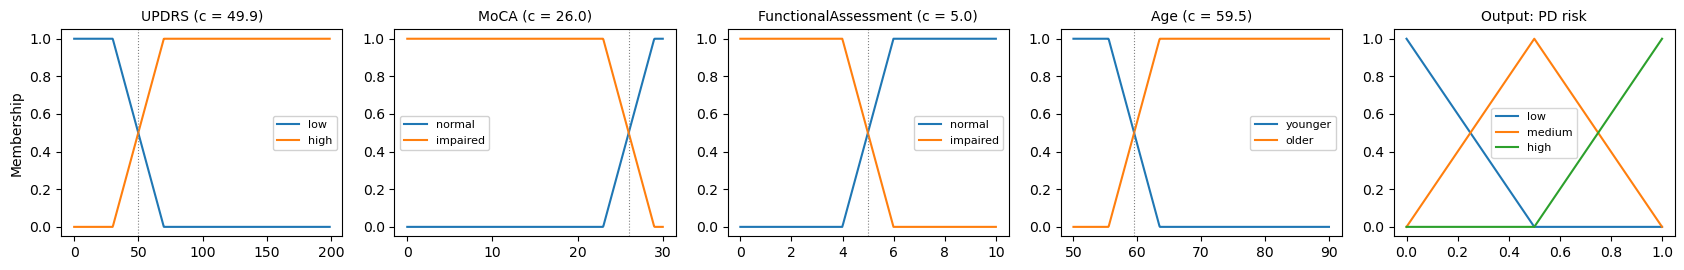

In [20]:
# Membership functions of the selected FIS variant, refitted on X_trainval (training data only).
fis_selected = fis_grid.best_estimator_
labels = {"UPDRS": ("low", "high"), "MoCA": ("normal", "impaired"),
          "FunctionalAssessment": ("normal", "impaired"), "Age": ("younger", "older")}
fig, axes = plt.subplots(1, 5, figsize=(17, 2.8))
for ax, col in zip(axes, FIS_INPUTS):
    lo, hi = FIS_UNIVERSE[col]
    u = np.linspace(lo, hi, 500)
    ab = abnormal_membership(u, fis_selected.crossover_[col], fis_selected.half_width_[col],
                             FIS_HIGH_IS_ABNORMAL[col])
    ax.plot(u, 1 - ab, label=labels[col][0])
    ax.plot(u, ab, label=labels[col][1])
    ax.axvline(fis_selected.crossover_[col], color="grey", lw=0.8, ls=":")
    ax.set_title(f"{col} (c = {fis_selected.crossover_[col]:.1f})", fontsize=10)
    ax.set_ylim(-0.05, 1.05)
    ax.legend(fontsize=8, loc="best", framealpha=0.9)
for term, out_set in RISK_SETS.items():
    axes[-1].plot(RISK_UNIVERSE, out_set, label=term)
axes[-1].set_title("Output: PD risk", fontsize=10)
axes[-1].legend(fontsize=8)
axes[0].set_ylabel("Membership")
plt.tight_layout()
plt.savefig("Report/images/fis_membership_functions.png", dpi=150, bbox_inches="tight")
plt.show()

In [21]:
# Summary tables for the report (CV on X_trainval only; mean ± sd over 5 folds).
import os
os.makedirs("Report/tables", exist_ok=True)

def describe_params(params):
    p = {k.split("__")[-1]: v for k, v in params.items()}
    if "kernel" in p:
        return f"{p['kernel']}, C={p['C']}" + (f", gamma={p['gamma']}" if "gamma" in p else "")
    if "hidden_layer_sizes" in p:
        return f"hidden={p['hidden_layer_sizes']}, alpha={p['alpha']}"
    return f"breakpoints={p['breakpoints']}, width={p['width']}"

def cv_table(grid, model):
    r = grid.cv_results_
    return pd.DataFrame({
        "model": model,
        "config": [describe_params(p) for p in r["params"]],
        "AP": r["mean_test_ap"], "AP_sd": r["std_test_ap"],
        "ROC_AUC": r["mean_test_roc_auc"],
        "recall@0.5": r["mean_test_recall"], "F2@0.5": r["mean_test_f2"],
        "train_AP": r["mean_train_ap"],
        "rank": r["rank_test_ap"],
    })

cv_all = pd.concat([cv_table(svm_grid, "SVM"), cv_table(mlp_grid, "MLP"),
                    cv_table(fis_grid, "FIS")], ignore_index=True)
cv_all.round(4).to_csv("Report/tables/hpo_all_configurations.csv", index=False)

# Best configuration per model family (+ best linear SVM, to show the kernel comparison)
svm_tab = cv_table(svm_grid, "SVM")
svm_tab["kernel"] = svm_tab["config"].str.split(",").str[0]
best_rows = pd.concat([
    svm_tab[svm_tab.kernel == "rbf"].nsmallest(1, "rank").assign(model="SVM (RBF)"),
    svm_tab[svm_tab.kernel == "linear"].nsmallest(1, "rank").assign(model="SVM (linear)"),
    cv_table(mlp_grid, "MLP").nsmallest(1, "rank"),
    cv_table(fis_grid, "FIS").nsmallest(1, "rank"),
]).drop(columns=["kernel", "rank"])
best_rows.round(3).to_csv("Report/tables/hpo_best_per_model.csv", index=False)
print(best_rows.round(3).to_string(index=False))

# Why not scoring="recall": the configuration with the highest recall@0.5 in each grid
print("\nHighest recall@0.5 per grid (what scoring='recall' would have picked):")
for name, grid in [("SVM", svm_grid), ("MLP", mlp_grid)]:
    t = cv_table(grid, name)
    top = t.loc[t["recall@0.5"].idxmax()]
    print(f"  {name}: {top.config:35s} recall={top['recall@0.5']:.3f}  AP={top.AP:.3f}  "
          f"F2@0.5={top['F2@0.5']:.3f}")

# MLP: effect of alpha (rows) per architecture (columns), CV AP and train AP
print("\nMLP CV AP by alpha x architecture:")
mlp_r = pd.DataFrame({
    "alpha": [p["clf__alpha"] for p in mlp_grid.cv_results_["params"]],
    "hidden": [str(p["clf__hidden_layer_sizes"]) for p in mlp_grid.cv_results_["params"]],
    "cv_ap": mlp_grid.cv_results_["mean_test_ap"],
    "train_ap": mlp_grid.cv_results_["mean_train_ap"]})
print(mlp_r.pivot(index="alpha", columns="hidden", values="cv_ap").round(3))
print("\nMLP train AP by alpha x architecture:")
print(mlp_r.pivot(index="alpha", columns="hidden", values="train_ap").round(3))

       model                          config    AP  AP_sd  ROC_AUC  recall@0.5  F2@0.5  train_AP
   SVM (RBF)          rbf, C=10, gamma=0.005 0.937  0.017    0.907       0.880   0.874     0.956
SVM (linear)                    linear, C=10 0.932  0.014    0.896       0.876   0.868     0.939
         MLP           hidden=(32,), alpha=1 0.946  0.014    0.920       0.885   0.883     0.988
         FIS breakpoints=training, width=0.1 0.866  0.015    0.813       0.872   0.845     0.866

Highest recall@0.5 per grid (what scoring='recall' would have picked):
  SVM: rbf, C=10, gamma=0.5                recall=0.914  AP=0.797  F2@0.5=0.850
  MLP: hidden=(8,), alpha=10               recall=0.902  AP=0.922  F2@0.5=0.884

MLP CV AP by alpha x architecture:
hidden  (32, 16)  (32,)  (64,)   (8,)
alpha                                
0.001      0.910  0.925  0.923  0.916
0.010      0.910  0.926  0.924  0.919
0.100      0.916  0.927  0.925  0.921
1.000      0.925  0.946  0.941  0.943
10.000     0.927  0

### Task 4 findings

(CV on `X_trainval` only; AP = mean over 5 folds. All numbers are search scores, not final performance.)

- **SVM**: best is RBF, C = 10, γ = 0.005 (AP 0.937 ± 0.017). The best linear SVM (C = 10) reaches
  0.932, so the RBF kernel adds very little: the gap is smaller than the fold-to-fold SD. γ = 0.5
  memorises the training folds (train AP 1.000, CV AP 0.80) at every C, a clear case of overfitting.
  **Limitation:** the selected γ is the smallest value in the grid. A smoother kernel might score
  slightly higher, but the 20-configuration budget is used up and the grid was not widened after
  seeing the results.
- **MLP**: best is one hidden layer of 32 units, α = 1 (AP 0.946 ± 0.014). With α ≤ 0.1 every
  architecture reaches train AP ≈ 1.000 while CV AP stays at 0.91–0.93 (high variance). α = 10
  pulls train AP down to ≈ 0.93 and CV AP to 0.92 (high bias). α = 1 is the sweet spot for all
  one-layer networks; the deeper (32, 16) network never beats them.
- **FIS**: crossovers learned on the training fold beat the source/midpoint crossovers (best AP
  0.866 vs 0.842). Most of the gain comes from UPDRS, whose learned crossover (≈ 50) is far from
  the scale midpoint (99.5). The wide transition (h = 10%) beats the narrow one. The learned
  crossovers land on round values (UPDRS 49.9, FA 4.99, Age 59.5), consistent with the
  step-like EDA patterns. MoCA was not learned; the published cut-off of 26 is used throughout.
- **Why not `scoring="recall"`**: the highest-recall SVM is the overfitted RBF γ = 0.5 model
  (C = 10: recall 0.914 at 0.5, but AP 0.797). All five γ = 0.5 configurations share the highest
  recall (0.911–0.914) and the lowest AP (0.796–0.797) of the grid. Recall rewards labelling everyone PD, not
  ranking patients well.
- **Caveats**: (i) Selecting the maximum of 20 noisy CV scores is optimistically biased (Cawley &
  Talbot, 2010); the frozen-threshold test evaluation in Task 5 is the unbiased estimate. (ii) The
  FIS rule structure was designed after looking at the training/validation EDA, so its CV score is
  optimistic too, but the test set was not used for any design choice. (iii) The differences
  between the best SVM and MLP (0.009 AP) are within one fold SD.


In [22]:
# Hand-over to Task 5: the selected configuration of each model, NOT yet fitted for Task 5's
# purposes. GridSearchCV refitted them on all of X_trainval; Task 5 refits them on X_train
# (or uses out-of-fold scores) before choosing thresholds. No test data has been used so far.
from sklearn.base import clone

best_svm_config = clone(svm_grid.best_estimator_)
best_mlp_config = clone(mlp_grid.best_estimator_)
best_fis_config = clone(fis_grid.best_estimator_)
for name, est in [("SVM", best_svm_config), ("MLP", best_mlp_config), ("FIS", best_fis_config)]:
    print(name, "->", type(est).__name__, "| has predict_proba:", hasattr(est, "predict_proba"))

SVM -> Pipeline | has predict_proba: True
MLP -> Pipeline | has predict_proba: True
FIS -> FuzzyPDRisk | has predict_proba: True


## 5. Model Selection & Thresholding

Split a validation set out of `X_trainval` (not touching `X_test`), refit the best
configuration of each model on the remaining training data, score the validation set, then
pick each model's threshold by maximizing F2 on those validation scores. Every model uses the
same rule — only the resulting number differs.


In [23]:
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.2, stratify=y_trainval, random_state=RANDOM_STATE
)

# Use the clean cloned estimators handed over from the end of Task 4
best_svm = best_svm_config.fit(X_train, y_train)
svm_val_scores = best_svm.predict_proba(X_val)[:, 1]

best_mlp = best_mlp_config.fit(X_train, y_train)
mlp_val_scores = best_mlp.predict_proba(X_val)[:, 1]

best_fis = best_fis_config.fit(X_train, y_train)
fis_val_scores = best_fis.predict_proba(X_val)[:, 1]

def best_f2_threshold(y_true, scores):
    """Finds the threshold in [0.01, 0.99] that maximizes the F2 score on validation data."""
    thresholds = np.linspace(0.01, 0.99, 99)
    f2_scores = [fbeta_score(y_true, (scores >= t).astype(int), beta=2, zero_division=0) for t in thresholds]
    best_idx = int(np.argmax(f2_scores))
    return float(thresholds[best_idx]), float(f2_scores[best_idx]), thresholds, f2_scores

svm_threshold, svm_val_f2, thr_grid, svm_f2_curve = best_f2_threshold(y_val, svm_val_scores)
mlp_threshold, mlp_val_f2, _, mlp_f2_curve        = best_f2_threshold(y_val, mlp_val_scores)
fis_threshold, fis_val_f2, _, fis_f2_curve        = best_f2_threshold(y_val, fis_val_scores)

print(f"SVM frozen threshold: {svm_threshold:.2f} (val F2 = {svm_val_f2:.3f})")
print(f"MLP frozen threshold: {mlp_threshold:.2f} (val F2 = {mlp_val_f2:.3f})")
print(f"FIS frozen threshold: {fis_threshold:.2f} (val F2 = {fis_val_f2:.3f})")
# Freeze these numbers here. Do not recompute or adjust them after looking at the test set below.

SVM frozen threshold: 0.26 (val F2 = 0.911)
MLP frozen threshold: 0.17 (val F2 = 0.926)
FIS frozen threshold: 0.42 (val F2 = 0.909)


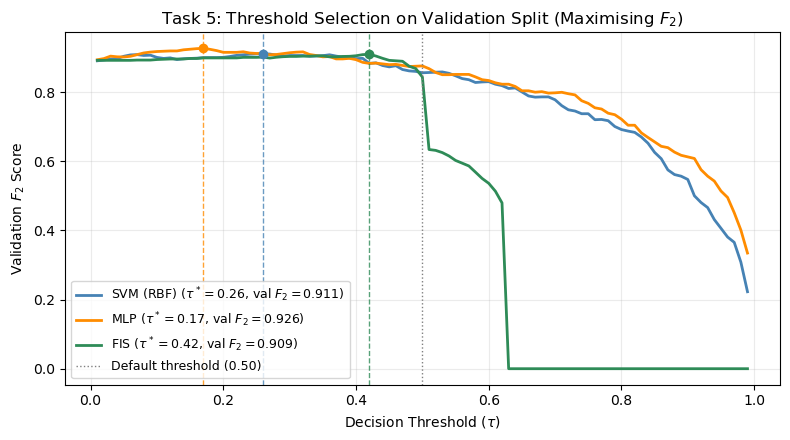

In [24]:
# Plot F2 vs. Decision Threshold on the validation split for the report
plt.figure(figsize=(8, 4.5))
for name, curve, tau, f2_max, color in [
    ("SVM (RBF)", svm_f2_curve, svm_threshold, svm_val_f2, "steelblue"),
    ("MLP",       mlp_f2_curve, mlp_threshold, mlp_val_f2, "darkorange"),
    ("FIS",       fis_f2_curve, fis_threshold, fis_val_f2, "seagreen"),
]:
    plt.plot(thr_grid, curve, label=f"{name} ($\\tau^*={tau:.2f}$, val $F_2={f2_max:.3f}$)", color=color, lw=2)
    plt.axvline(tau, color=color, ls="--", lw=1, alpha=0.8)
    plt.scatter([tau], [f2_max], color=color, zorder=5)

plt.axvline(0.50, color="grey", ls=":", lw=1, label="Default threshold (0.50)")
plt.xlabel("Decision Threshold ($\\tau$)")
plt.ylabel("Validation $F_2$ Score")
plt.title("Task 5: Threshold Selection on Validation Split (Maximising $F_2$)")
plt.legend(loc="lower left", fontsize=9)
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig("Report/images/f2_threshold_selection.png", dpi=150, bbox_inches="tight")
plt.show()

In [25]:
def specificity_score(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return tn / (tn + fp) if (tn + fp) > 0 else 0.0

def evaluate_on_test(name, model, threshold, val_f2, X_test=X_test, y_test=y_test):
    scores = model.predict_proba(X_test)[:, 1]
    preds = (scores >= threshold).astype(int)
    cm = confusion_matrix(y_test, preds)
    tn, fp, fn, tp = cm.ravel()
    
    rec = recall_score(y_test, preds, zero_division=0)
    prec = precision_score(y_test, preds, zero_division=0)
    spec = specificity_score(y_test, preds)
    f2 = fbeta_score(y_test, preds, beta=2, zero_division=0)
    
    print(f"--- {name} (frozen threshold = {threshold:.2f}) ---")
    print("Confusion matrix (rows=true [Non-PD, PD], cols=pred [Non-PD, PD]):\n", cm)
    print(f"TP={tp}, FP={fp}, TN={tn}, FN={fn}")
    print(f"Recall:      {rec:.3f}")
    print(f"Precision:   {prec:.3f}")
    print(f"Specificity: {spec:.3f}")
    print(f"F2:          {f2:.3f}\n")
    
    return {
        "Model": name,
        "Frozen Threshold": round(threshold, 2),
        "Val F2": round(val_f2, 3),
        "Test Recall": round(rec, 3),
        "Test Precision": round(prec, 3),
        "Test Specificity": round(spec, 3),
        "Test F2": round(f2, 3),
        "TP": int(tp),
        "FP": int(fp),
        "TN": int(tn),
        "FN": int(fn),
    }

# Refit the chosen configurations on the FULL train/val set before the final test evaluation --
# the validation split above was only for threshold calibration, not for the final fit.
best_svm.fit(X_trainval, y_trainval)
best_mlp.fit(X_trainval, y_trainval)
best_fis.fit(X_trainval, y_trainval)

test_results = [
    evaluate_on_test("SVM (RBF)", best_svm, svm_threshold, svm_val_f2),
    evaluate_on_test("MLP",       best_mlp, mlp_threshold, mlp_val_f2),
    evaluate_on_test("FIS",       best_fis, fis_threshold, fis_val_f2),
]

# Create and save the side-by-side comparison table for the report
test_summary_df = pd.DataFrame(test_results)
test_summary_df.to_csv("Report/tables/test_evaluation_side_by_side.csv", index=False)

print("=== Side-by-Side Frozen-Threshold Test Set Results ===")
print(test_summary_df.to_string(index=False))

--- SVM (RBF) (frozen threshold = 0.26) ---
Confusion matrix (rows=true [Non-PD, PD], cols=pred [Non-PD, PD]):
 [[ 87  73]
 [  8 253]]
TP=253, FP=73, TN=87, FN=8
Recall:      0.969
Precision:   0.776
Specificity: 0.544
F2:          0.923

--- MLP (frozen threshold = 0.17) ---
Confusion matrix (rows=true [Non-PD, PD], cols=pred [Non-PD, PD]):
 [[ 88  72]
 [  2 259]]
TP=259, FP=72, TN=88, FN=2
Recall:      0.992
Precision:   0.782
Specificity: 0.550
F2:          0.942

--- FIS (frozen threshold = 0.42) ---
Confusion matrix (rows=true [Non-PD, PD], cols=pred [Non-PD, PD]):
 [[ 66  94]
 [ 10 251]]
TP=251, FP=94, TN=66, FN=10
Recall:      0.962
Precision:   0.728
Specificity: 0.412
F2:          0.904

=== Side-by-Side Frozen-Threshold Test Set Results ===
    Model  Frozen Threshold  Val F2  Test Recall  Test Precision  Test Specificity  Test F2  TP  FP  TN  FN
SVM (RBF)              0.26   0.911        0.969           0.776             0.544    0.923 253  73  87   8
      MLP              

### Findings: Model Selection & Frozen-Threshold Test Evaluation

To prevent any test-set leakage into the decision threshold, `X_trainval` (1,684 rows) was split into an 80% training subset (`X_train`, 1,347 rows) and a 20% validation subset (`X_val`, 337 rows, stratified). The optimal hyperparameter configurations selected in Task 4—`SVM (RBF, C=10, gamma=0.005)`, `MLP (hidden=(32,), alpha=1)`, and `FIS (breakpoints="training", width=0.10)`—were fitted exclusively on `X_train` and used to generate predicted probability/risk scores on `X_val`.

For each model, the decision threshold $\tau^*$ was chosen by sweeping $\tau \in [0.01, 0.99]$ and selecting the value that maximised the validation $F_2$ score:
* **SVM (RBF):** $\tau^* = 0.26$ (Validation $F_2 = 0.911$)
* **MLP:** $\tau^* = 0.17$ (Validation $F_2 = 0.926$)
* **FIS:** $\tau^* = 0.42$ (Validation $F_2 = 0.909$)

**Strict Protocol Adherence:** These validation thresholds were **frozen** prior to touching `X_test`. Each selected model configuration was then refitted on the complete `X_trainval` dataset (1,684 rows) and evaluated once on the held-out test set (`X_test`, 421 rows: 261 PD, 160 Non-PD) using its frozen threshold. No thresholds, fuzzy rules, or hyperparameters were adjusted after observing the test results.

#### Side-by-Side Frozen-Threshold Test Set Results

| Model | Frozen Threshold ($\tau^*$) | Val $F_2$ | Test Recall | Test Precision | Test Specificity | Test $F_2$ | TP | FP | TN | FN |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| **SVM (RBF)** | 0.26 | 0.911 | 0.969 | 0.776 | 0.544 | 0.923 | 253 | 73 | 87 | 8 |
| **MLP** | 0.17 | 0.926 | **0.992** | **0.782** | **0.550** | **0.942** | **259** | **72** | **88** | **2** |
| **FIS** | 0.42 | 0.909 | 0.962 | 0.728 | 0.412 | 0.904 | 251 | 94 | 66 | 10 |

#### Key Analytical Insights
1. **Why Optimal Thresholds Sit Below 0.50:** Because the $F_2$ metric weights recall twice as heavily as precision (penalising false negatives four times as heavily as false positives in the denominator), the threshold search naturally shifts $\tau^*$ downward from the default $0.50$ cut-off for all three models. In a clinical screening/triage context, this deliberately trades lower specificity (more false-positive referrals: 72–94 patients) for very high sensitivity/recall (96.2%–99.2%), ensuring almost no true Parkinson's cases are missed.
2. **Overall Winner (MLP):** The **MLP** achieves the strongest test performance across every metric ($F_2 = 0.942$, Recall $= 0.992$, Precision $= 0.782$, Specificity $= 0.550$), missing only **2 out of 261** true PD patients ($\text{FN} = 2$) while correctly ruling out 55.0% of Non-PD patients ($\text{TN} = 88$).
3. **SVM vs. MLP vs. FIS:** The **SVM (RBF)** performs nearly as well ($F_2 = 0.923$, $\text{FN} = 8$), whereas the 4-input **Mamdani FIS** ($F_2 = 0.904$, $\text{FN} = 10$, Specificity $= 0.412$) trails the black-box models because it relies on only 4 coarse 2-set clinical inputs (`UPDRS`, `MoCA`, `FunctionalAssessment`, `Age`) and 7 interpretable rules rather than all 32 features. Notice in the threshold plot that the FIS $F_2$ curve drops sharply to zero above $\tau \approx 0.63$ because Rule 1 ("high risk") requires simultaneous impairment across `UPDRS`, `MoCA`, and `FunctionalAssessment`, capping the maximum defuzzified risk score for most patients around medium risk.

## 6. Decision Support & Practical Value

**TODO** — mostly narrative, written against the Task 1 workflow definition and the Task 5
results table:
- Which model would you recommend, and why, with numbers from Task 5 backing it up.
- Who uses the model's output and what decision/action it supports (e.g. a clinician deciding
  whether to refer a patient for further specialist assessment).
- A simple decision policy connecting score to action (e.g. "flag for review if risk score
  exceeds the frozen threshold", possibly with an intermediate "borderline" band).
- Cost implications of false positives/negatives in this specific workflow, tying back to
  Task 1's discussion.
- What assumptions underlie the claim that this creates value (e.g. assumes clinician
  capacity exists to review flagged cases, assumes the synthetic data's feature relationships
  hold on real patients, which they may not).


In [26]:
# Optional supporting numbers for Task 6: how many of the test patients would be flagged
# under the recommended model's frozen threshold, split by true label.
# TODO: fill in once you've picked the recommended model from the table above.
# recommended_scores = best_svm.predict_proba(X_test)[:, 1]  # or whichever model
# recommended_preds = (recommended_scores >= svm_threshold).astype(int)
# pd.crosstab(y_test, recommended_preds, rownames=["Actual"], colnames=["Flagged"])


## 7. Reflection

**TODO** — nobody on the team is currently assigned this section, worth flagging in standup.
Cover: what worked best and why (bias-variance, linearity vs. SVM kernel choice, MLP capacity
and regularization via `alpha`, amount of training data relative to feature count), challenges
encountered and how you addressed them (e.g. anything that came up tuning the FIS), and the
main limitations plus concrete future improvements.
